# 09 · Горизонт и дисконтирование

Шаг 10 плана. Кривая «ответ vs горизонт» для 6/12/24 месяцев; 6 и 12 наблюдаются,
24 — экстраполяция. Ставка дисконтирования — 10 % годовых, месячная
`(1.10)^(1/12)−1 = 0.797 %`. Формула `m·r/(1+d−r)` вместо `m/churn` — потому что
`m/churn` это тот же геометрический ряд при `d = 0`.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import json
from inspect import signature
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_LTV, PROCESSED, RANDOM_SEED, figures
from features import (CUTOFF_DATE, HORIZON_MONTHS, B3_T_DAYS, B3_FIT_MONTHS,
                      DAYS_IN_AGE_MONTH, split_transactions, calibration_features,
                      calibration_revenue, build_target, lifecycle_transactions,
                      first_purchase_dates, pre_first_mask, customer_country,
                      cohort_tables, pooled_curve, extend_survival,
                      extend_cumulative_revenue, age_months)
from metrics import (gini, top_capture, top_lift, decile_capture, lorenz_points,
                     mae, rmse, calibration_ratio, model_metrics, bootstrap_ci,
                     bootstrap_diff, calibration_by, coverage_at_top,
                     smallest_segment_for_coverage, shrink_predictions)
from models import (fit_bgnbd, fit_mbg_nbd, fit_pareto_nbd, fit_gamma_gamma,
                    bgnbd_loglik, bgnbd_expected_purchases, mbg_nbd_loglik,
                    mbg_nbd_expected_purchases, pareto_nbd_loglik,
                    pareto_nbd_expected_purchases, gamma_gamma_loglik,
                    gamma_gamma_mean, gamma_gamma_conditional_spend,
                    monthly_expected_purchases, discounted_revenue, aic)
from plots import (plot_split_timeline, plot_lorenz, plot_model_comparison,
                   plot_calibration_by_decile, plot_horizon, plot_segments,
                   plot_shrinkage, plot_posterior)
FIG = figures(CASE_LTV); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(RANDOM_SEED)
tx = pd.read_parquet(PROCESSED / 'transactions.parquet')

split = pd.read_parquet(PROCESSED / 'ltv_split.parquet')
purch = pd.read_parquet(PROCESSED / 'purchases.parquet')
spend = pd.read_parquet(PROCESSED / 'spend.parquet')
summary = pd.read_csv(PROCESSED / 'bgnbd_summary.csv', index_col=0)
d = split.join(purch).join(spend[['spend_main']])
x = d.frequency.to_numpy(float); t_x = d.recency.to_numpy(float); T = d['T'].to_numpy(float)
params = tuple(float(summary.loc[k, 'mean']) for k in ['r', 'alpha', 'a', 'b'])


## Кривая «ответ vs горизонт»

In [2]:
rows = []
for H in [6, 12, 24]:
    pred = bgnbd_expected_purchases(params, x, t_x, T, 30 * H) * d.spend_main.to_numpy()
    observed = np.nan
    if H <= 12:
        observed = build_target(tx, d.index, CUTOFF_DATE, H).revenue_holdout.mean()
    rows.append({'horizon': H, 'predicted': pred.mean(), 'observed': observed})
curve = pd.DataFrame(rows)
curve.round(1)


,horizon,predicted,observed
0,6,1035.9,636.8
1,12,2071.9,1539.3
2,24,4143.7,NaN


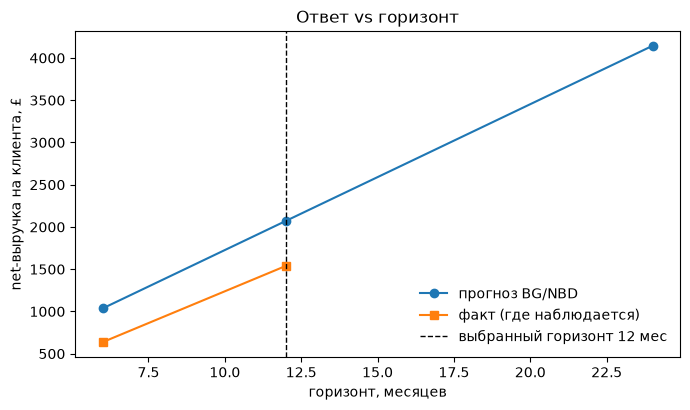

In [3]:
plot_horizon(curve, FIG / '15-horizon-curve.png', chosen=12)
plt.show()


6 месяцев наблюдается, 12 — тоже; 24 месяца данных нет (окно кончилось
2011-12-09), это экстраполяция модели. 12 выбрано как самый длинный полностью
наблюдаемый горизонт и типичный цикл планирования бюджета.

## Дисконтирование

In [4]:
annual_rate = 0.10
d_m = (1 + annual_rate) ** (1 / 12) - 1
monthly_purch = monthly_expected_purchases(bgnbd_expected_purchases, params, x, t_x, T, 12)
monthly_rev = monthly_purch * d.spend_main.to_numpy()[None, :]
pv = discounted_revenue(monthly_rev, annual_rate)
undiscounted = monthly_rev.sum(axis=0)
print('месячная ставка:', round(d_m, 5), f'({d_m:.3%})')
print('средняя 12-мес выручка: undiscounted', round(undiscounted.mean(), 1),
      '£ · PV', round(pv.mean(), 1), '£ · скидка', f'{1 - pv.mean()/undiscounted.mean():.1%}')
print('Gini undiscounted:', round(gini(d.revenue_holdout, undiscounted), 4),
      '· Gini PV:', round(gini(d.revenue_holdout, pv), 4))


месячная ставка: 0.00797 (0.797%)
средняя 12-мес выручка: undiscounted 2071.9 £ · PV 1976.2 £ · скидка 4.6%
Gini undiscounted: 0.6972 · Gini PV: 0.6972


## Псевдо-holdout: почему нет глобальной поправки

Проверяю, можно ли оценить смещение уровня внутри калибровки: фичу BG/NBD на
более коротком окне и предсказываю следующий период. Если псевдо-holdout даёт
стабильный коэффициент, его можно перенести на основной holdout; если нет —
глобальная поправка не обоснована.

In [5]:
def pseudo_ratio(cutoff, months):
    f = calibration_features(tx, cutoff)
    r = calibration_revenue(tx, cutoff)
    tgt = build_target(tx, f.index, cutoff, months)
    dd = f.join(tgt).join(r.rename('rev_cal'))
    dd = dd[dd['T'] > 0]
    xx = dd.frequency.to_numpy(float); tt = dd.recency.to_numpy(float); TT = dd['T'].to_numpy(float)
    p, _ = fit_bgnbd(xx, tt, TT)
    gg = dd[dd.frequency >= 1]
    pg, _ = fit_gamma_gamma(gg.frequency.to_numpy(float), gg.monetary.to_numpy(float))
    sp = gamma_gamma_conditional_spend(pg, xx, dd.monetary.to_numpy(float))
    pred = bgnbd_expected_purchases(p, xx, tt, TT, 30 * months) * sp
    return len(dd), pred.mean() / dd.revenue_holdout.mean(), gini(dd.revenue_holdout, pred)

pseudo_rows = []
for label, c, h in [('6/6', pd.Timestamp('2010-06-01'), 6), ('9/3', pd.Timestamp('2010-09-01'), 3)]:
    n, ratio, g = pseudo_ratio(c, h)
    pseudo_rows.append({'window': label, 'n': n, 'calibration_ratio': ratio, 'gini': g})
pseudo = pd.DataFrame(pseudo_rows)
pseudo.round(3)


,window,n,calibration_ratio,gini
0,6/6,2684,0.857,0.580
1,9/3,3299,0.703,0.572


Псевдо-holdout даёт calibration ratio 0.86 (6/6) и 0.70 (9/3), а основной
holdout — 1.36. Направление ошибки не переносится: короткое окно недооценивает,
12-месячное переоценивает. Глобальную поправку по калибровке не применяю;
уровень остаётся ограничением, а решение строится на ranking.

## Почему не `m / churn`, а `m·r/(1+d−r)`

`m/churn` — это сумма геометрического ряда `m + m·r + m·r² + …` при `d = 0`.
С дисконтированием каждый член делится на `(1+d)^k`, и сумма равна
`m·r/(1+d−r)`. При `r = 0.96` и `d = 0.797 %` разница с `m/churn` — около 20 %;
при более высоком удержании ошибка растёт.

In [6]:
r = 0.96
m = 1.0
formula = m * r / (1 + d_m - r)
m_over_churn = m / (1 - r)
print('m·r/(1+d−r):', round(formula, 3), '· m/churn:', round(m_over_churn, 3),
      '· разница:', f'{formula/m_over_churn - 1:.1%}')
assert formula < m_over_churn


m·r/(1+d−r): 20.011 · m/churn: 25.0 · разница: -20.0%


In [7]:
curve.to_csv(PROCESSED / 'horizon_curve.csv', index=False)
pd.DataFrame({'pv': pv, 'undiscounted': undiscounted}, index=d.index).to_parquet(PROCESSED / 'discounted.parquet')


Дисконтирование не меняет порядок клиентов (общая кривая скидок), поэтому
ranking-метрики от него не зависят; меняется уровень CLV и решение о CAC.